# Lezione 07 — Inflazione e tassi stocastici: pricing Monte Carlo di un inflation-linked bond

## 1. Sintesi del Caso, Domanda Quantitativa e Informazione Disponibile

### Contesto del Caso
Il lavoro riguarda la valutazione finanziaria di un'obbligazione indicizzata all'inflazione (inflation-linked bond) con cedole semestrali indicizzate e protezione del capitale nominale a scadenza mediante un floor. La valutazione dipende congiuntamente da due fattori di rischio stocastici e correlati:
- il **tasso istantaneo di inflazione** $i_t$, descritto da un processo di Ornstein--Uhlenbeck (OU);
- il **tasso nominale istantaneo privo di rischio** $r_t$, descritto da un processo di Cox--Ingersoll--Ross (CIR).

### Domanda Quantitativa
> **Qual è il valore corrente dell'inflation-linked bond ottenuto mediante simulazione Monte Carlo, e quale ruolo assumono l'indicizzazione, il rimborso protetto e la dipendenza tra inflazione e tasso nominale?**

### Variabile Finale e Informazione Disponibile
- **Variabile finale di interesse:** Il prezzo Monte Carlo stimato $\widehat V_M$, ottenuto come media sui percorsi simulati dei valori attuali dei flussi di cassa del titolo (cedole stocastiche e rimborso del capitale a scadenza), unitamente alla sua misura di precisione numerica (errore standard e intervallo di confidenza al 95%).
- **Informazione disponibile:** 
  - Dinamiche continue dei due fattori di rischio:
    $$di_t = \kappa_i(\theta_i - i_t)\,dt + \sigma_i\,dW_t^{(i)}$$
    $$dr_t = \kappa_r(\theta_r - r_t)\,dt + \sigma_r\sqrt{r_t}\,dW_t^{(r)}$$
    con shock correlati $dW_t^{(i)}dW_t^{(r)} = \rho\,dt$.
  - Struttura del contratto: valore facciale $N=100$, scadenza $T=5$ anni, tasso cedolare annuo $c=1,5\%$ con cedole semestrali non protette dalla deflazione $C_{t_j} = \frac{c}{2} N J_{t_j}$, rimborso del capitale protetto da floor $R_T = N \max(J_T, 1)$, dove $J_t = \exp\left(\int_0^t i_s\,ds\right)$ è il fattore di indicizzazione.
  - Parametri di simulazione e di mercato definiti a fini didattici: $i_0=0,025$, $\kappa_i=0,80$, $\theta_i=0,020$, $\sigma_i=0,015$, $r_0=0,030$, $\kappa_r=1,20$, $\theta_r=0,030$, $\sigma_r=0,10$, $\rho=0,25$, $\Delta t = 1/12$, $M=50.000$, seed $= 12345$.

---

## 2. Quantità da Stimare o Calcolare

1. **Prezzo Monte Carlo del bond** ($\widehat V_M$).
2. **Errore standard Monte Carlo** del prezzo $SE(\widehat V_M)$ e relativo **intervallo di confidenza al 95%**.
3. **Valore attuale medio delle cedole** ($\widehat{PV}_C$).
4. **Valore attuale medio del rimborso del capitale** ($\widehat{PV}_R$).
5. **Probabilità simulata di deflazione cumulata a scadenza**, $\widehat{\mathbb P}(J_T < 1)$.
6. **Media e deviazione standard simulate** delle variabili terminali $i_T$, $r_T$ e $J_T$.

---

## 3. Output Richiesti

### Tabelle

1. **Tabella 1:** Tabella dei parametri del caso.
2. **Tabella 2:** Tabella di sintesi del pricing (valore attuale medio delle cedole, valore attuale medio del rimborso, prezzo Monte Carlo del bond).
3. **Tabella 3:** Tabella di diagnostica Monte Carlo per $M = 1.000, 5.000, 10.000, 50.000$ (prezzo stimato ed errore standard stimato).
4. **Tabella 4:** Tabella delle statistiche terminali di $i_T$, $r_T$ e $J_T$.

### Grafici

1. **Figura 1:** Traiettorie simulate del tasso di inflazione $i_t$.
2. **Figura 2:** Traiettorie simulate del tasso nominale $r_t$.
3. **Figura 3:** Distribuzione simulata del fattore di indicizzazione terminale $J_T$.
4. **Figura 4:** Distribuzione simulata dei valori attuali $V^{(k)}$.
5. **Figura 5:** Grafico di convergenza della stima Monte Carlo al crescere di $M$.

---

## 4. Controlli Richiesti

1. **Controllo 1 (Correlazione empirica):** Verifica che la correlazione empirica degli shock simulati sia coerente con $\rho = 0,25$.
2. **Controllo 2 (Positività del fattore di indicizzazione):** Verifica che $J_{t_j}^{(k)} > 0$ per ogni replica $k$ e per ogni data $t_j$.
3. **Controllo 3 (Rispetto del floor sul capitale):** Verifica che il rimborso soddisfi $R_T^{(k)} \geq N$ per ogni replica $k$.
4. **Controllo 4 (Rilevazione tassi negativi nel CIR):** Conteggio e documentazione di eventuali valori negativi di $r_t$ prodotti dalla discretizzazione numerica, senza imporre automaticamente $r_t = 0$.
5. **Controllo 5 (Decomposizione del prezzo):** Verifica che la somma del valore attuale medio delle cedole e del valore attuale medio del rimborso uguagli il prezzo Monte Carlo ($\widehat V_M = \widehat{PV}_C + \widehat{PV}_R$).
6. **Controllo 6 (Tasso di convergenza Monte Carlo):** Verifica che l'errore standard diminuisca al crescere di $M$ in modo compatibile con l'ordine $\mathcal{O}(1/\sqrt{M})$.
7. **Controllo 7 (Sensibilità alla griglia temporale):** Verifica della stabilità del prezzo rispetto a un raffinamento della griglia temporale ($\Delta t$).

---

## 5. Vincolo della Scheda Caso

Si esplicita che la Scheda Caso costituisce la **specifica vincolante del lavoro**. Tutte le variabili, le formule, le relazioni funzionali, i parametri, gli output e i controlli stabiliti non devono essere modificati durante lo svolgimento dell'analisi.

# Flusso Logico-Teorico Risolutivo del Caso

Alla luce della Scheda Caso acquisita, la struttura concettuale del problema richiede la definizione precisa dei modelli stocastici, delle relazioni di dipendenza, della discretizzazione numerica, dei meccanismi contrattuali e delle metriche di aggregazione e controllo Monte Carlo.

Di seguito viene presentato il **Flusso logico-teorico risolutivo ordinato e completo**, strutturato in passi consequenziali.

---

### Tabella del Flusso Logico-Teorico Risolutivo

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| **1** | **Definizione delle dinamiche dei fattori di rischio** | **Inflazione (Ornstein-Uhlenbeck):**<br>$$di_t = \kappa_i(\theta_i - i_t)dt + \sigma_i dW_t^{(i)}$$<br>**Tasso nominale (CIR):**<br>$$dr_t = \kappa_r(\theta_r - r_t)dt + \sigma_r\sqrt{r_t}dW_t^{(r)}$$<br>Condizione di Feller: $2\kappa_r\theta_r \geq \sigma_r^2$. | Identificazione delle equazioni differenziali stocastiche (SDE) che governano l'evoluzione temporale dell'inflazione istantanea $i_t$ e del tasso privo di rischio $r_t$. | Tabella 1 (Parametri del caso) |
| **2** | **Modellizzazione della dipendenza tra gli shock** | **Correlazione browniana:**<br>$$dW_t^{(i)}dW_t^{(r)} = \rho dt$$<br>**Decomposizione di Cholesky (o combinazione lineare):**<br>$$dZ^{(i)} = dZ_1$$<br>$$dZ^{(r)} = \rho dZ_1 + \sqrt{1 - \rho^2}dZ_2$$<br>con $dZ_1, dZ_2 \sim \mathcal{N}(0,1)$ indipendenti. | Generazione di coppie di variate normali standard correlate per preservare la struttura di dipendenza tra gli shock dell'inflazione e dei tassi in ogni replica. | Controllo 1 (Correlazione empirica shock) |
| **3** | **Discretizzazione numerica delle traiettorie stocastiche** | **Schema di Eulero-Maruyama:**<br>$$i_{t+\Delta t} = i_t + \kappa_i(\theta_i - i_t)\Delta t + \sigma_i \sqrt{\Delta t} Z^{(i)}$$<br>$$r_{t+\Delta t} = r_t + \kappa_r(\theta_r - r_t)\Delta t + \sigma_r \sqrt{\max(r_t,0)\Delta t} Z^{(r)}$$ | Simulazione delle traiettorie su griglia temporale mensile $\Delta t = 1/12$. Gestione operativa della radice nel CIR mediante $\sqrt{\max(r_t,0)}$. | Figura 1 (Traiettorie $i_t$), Figura 2 (Traiettorie $r_t$), Controllo 4 (Conteggio $r_t < 0$) |
| **4** | **Integrazione numerica e fattori di indicizzazione e sconto** | **Fattore di indicizzazione stocastico:**<br>$$J_t = \exp\left(\int_0^t i_s ds\right) \approx \exp\left(\sum_{u=1}^{t/\Delta t} i_{u-1}\Delta t\right)$$<br>**Fattore di sconto stocastico:**<br>$$D(0,t) = \exp\left(-\int_0^t r_s ds\right) \approx \exp\left(-\sum_{u=1}^{t/\Delta t} r_{u-1}\Delta t\right)$$ | Calcolo dei fattori di indicizzazione $J_{t_j}^{(k)}$ e di sconto $D^{(k)}(0,t_j)$ lungo ciascuna singola traiettoria $k$. | Figura 3 (Distribuzione $J_T$), Controllo 2 (Positività $J_{t_j} > 0$) |
| **5** | **Determinazione dei flussi di cassa contrattuali** | **Cedole stocastiche ($t_j = 0.5, 1.0, \dots, 5.0$):**<br>$$C_{t_j} = \frac{c}{2} N J_{t_j}$$<br>**Rimborso a scadenza con Floor ($T = 5$):**<br>$$R_T = N \max(J_T, 1)$$ | Valutazione dei flussi pagati dall'obbligazione. Le cedole variano direttamente con l'indice dei prezzi (senza floor); il capitale garantisce il rimborso del valore facciale nominale $N$. | Controllo 3 (Floor capitale $R_T \geq N$) |
| **6** | **Valutazione Monte Carlo replica per replica** | **Valore attuale totale della replica $k$:**<br>$$V^{(k)} = \sum_{j=1}^{m} D^{(k)}(0,t_j) C_{t_j}^{(k)} + D^{(k)}(0,T) R_T^{(k)}$$<br>**Scomposizione nella singola replica:**<br>$$PV_C^{(k)} = \sum_{j=1}^{m} D^{(k)}(0,t_j) C_{t_j}^{(k)}, \quad PV_R^{(k)} = D^{(k)}(0,T) R_T^{(k)}$$ | Attualizzazione di tutti i flussi di cassa con i corrispondenti fattori di sconto stocastici all'interno della medesima replica $k$. | Figura 4 (Distribuzione dei valori attuali $V^{(k)}$) |
| **7** | **Aggregazione Monte Carlo, stima puntuale ed errore standard** | **Prezzo stimato:**<br>$$\widehat V_M = \frac{1}{M}\sum_{k=1}^M V^{(k)} = \widehat{PV}_C + \widehat{PV}_R$$<br>**Errore Standard:**<br>$$SE(\widehat V_M) = \frac{s_V}{\sqrt{M}}$$<br>**Intervallo di confidenza al 95%:**<br>$$\widehat V_M \pm 1,96 \, SE(\widehat V_M)$$ | Calcolo delle medie campionarie per ottenere il prezzo del bond, la quota cedole e la quota capitale, unitamente alle misure di incertezza campionaria. | Tabella 2 (Sintesi pricing), Tabella 4 (Statistiche terminali), Controllo 5 (Decomposizione prezzo) |
| **8** | **Analisi di convergenza e robustezza temporale** | **Proprietà di convergenza:**<br>$$SE(\widehat V_M) \propto \mathcal{O}\left(\frac{1}{\sqrt{M}}\right)$$<br>**Stabilità alla griglia:** confronto stime con $\Delta t$ e $\Delta t_{fine}$. | Verifica dell'accuratezza campionaria per differenti dimensioni di $M$ e della convergenza dello schema di discretizzazione temporale. | Tabella 3 (Diagnostica $M$), Figura 5 (Grafico convergenza), Controllo 6 (Tasso di convergenza $M$), Controllo 7 (Sensibilità $\Delta t$) |

---

### Note di Allineamento Teorico e Riscontro
1. **Completezza:** La sequenza integra tutti gli aspetti chiave richiesti dalla Scheda Caso: il legame tra le due SDE, la correlazione degli shock via decomposizione di Cholesky, la discretizzazione numerica appropriata per il processo CIR (con diagnostica dei valori negativi), l'integrazione traiettoria per traiettoria dei fattori $J_t$ e $D(0,t)$, la specificità del contratto (cedole non protette vs capitale protetto), e i controlli formali sia Monte Carlo ($M$) che temporali ($\Delta t$).
2. **Ordinamento:** L'ordine proposto parte dalle cause primarie (i processi stocastici dei fattori di rischio) fino ad arrivare alle quantità aggregate finali (prezzo, intervalli di confidenza, diagnostica e controlli di robustezza).
3. **Decisione finale:** Si ricorda che la convalida formale di questo flusso logico-teorico spetta allo studente.

# Scomposizione Operativa del Notebook in 6 Tappe Input-Output

La scomposizione del notebook è articolata nelle **6 tappe operative** definite dallo studente, integrando tutti gli oggetti teorici, gli output e i controlli richiesti dalla Scheda Caso vincolante.

---

### Tabella della Scomposizione Input-Output (6 Tappe)

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| **1** | **Inizializzazione dei parametri e della griglia temporale** | Acquisire e strutturare tutti i parametri contrattuali, di processo e di simulazione. | Testo della Scheda Caso | Parametri ($N, T, c, I_0, i_0, \kappa_i, \theta_i, \sigma_i, r_0, \kappa_r, \theta_r, \sigma_r, \rho, \Delta t, M, \text{seed}$) | Inizializzazione delle variabili, costruzione della griglia temporale mensile ($t_u$) e delle scadenze cedolari ($t_j$). | **Tabella 1** (Tabella dei parametri del caso) | Verifica della condizione di Feller ($2\kappa_r\theta_r \ge \sigma_r^2$) e correttezza formale delle variabili. | Tappe 2, 3, 4, 5, 6 | **Regime A/B** |
| **2** | **Simulazione congiunta dei fattori di rischio stocastici** | Simulare le traiettorie dell'inflazione $i_t$ e del tasso nominale $r_t$ sul numero di repliche $M$ e sulla griglia $\Delta t$. | Parametri da Tappa 1 | Processi OU e CIR, decomposizione di Cholesky, discretizzazione Eulero-Maruyama con $\sqrt{\max(r_t,0)}$ | Generazione di normali correlate e simulazione delle matrici delle traiettorie per $i_t$ ed $r_t$. | Matrici `i_paths` e `r_paths`, **Figura 1** (Traiettorie $i_t$), **Figura 2** (Traiettorie $r_t$) | **Controllo 1** (Correlazione empirica shock $\approx \rho=0.25$), **Controllo 4** (Rilevazione e conteggio $r_t < 0$) | Tappe 3, 4, 5, 6 | **Regime B** |
| **3** | **Calcolo dei fattori stocastici di indicizzazione e di sconto** | Trasformare le traiettorie simulate nei fattori $J_t$ e $D(0,t)$ mediante le formule discretizzate lungo ciascuna replica. | Matrici `i_paths`, `r_paths` da Tappa 2, $\Delta t$ da Tappa 1 | Somme di Riemann e approssimazione stocastica di $J_t = \exp\left(\int_0^t i_s ds\right)$ e $D(0,t) = \exp\left(-\int_0^t r_s ds\right)$ | Integrazione numerica lungo i percorsi per ottenere le matrici di indicizzazione e di sconto per ogni replica e data. | Matrici `J_paths` e `D_paths`, **Figura 3** (Distribuzione $J_T$) | **Controllo 2** (Verifica positività $J_{t_j}^{(k)} > 0$) | Tappe 4, 5 | **Regime B** |
| **4** | **Calcolo dei flussi contrattuali e dei valori attuali per replica** | Determinare le cedole stocastiche, il capitale protetto a scadenza e i relativi valori attuali per ciascuna replica $k$. | Matrici `J_paths`, `D_paths` da Tappa 3, $N, c$ da Tappa 1 | Cedole $C_{t_j} = \frac{c}{2} N J_{t_j}$, Rimborso protetto $R_T = N\max(J_T, 1)$, Valori attuali $PV_C^{(k)}, PV_R^{(k)}, V^{(k)}$ | Calcolo dei flussi alle scadenze, attualizzazione e somma replica per replica delle componenti cedole e capitale. | Vettori `PV_C`, `PV_R`, `V_k`, **Figura 4** (Distribuzione valori attuali $V^{(k)}$) | **Controllo 3** (Verifica floor sul capitale $R_T^{(k)} \ge N$) | Tappe 5, 6 | **Regime B** |
| **5** | **Stima del prezzo Monte Carlo e analisi delle statistiche** | Calcolare il prezzo del bond, l'errore standard, l'intervallo di confidenza al 95% e le statistiche delle variabili terminali. | Vettori `PV_C`, `PV_R`, `V_k` da Tappa 4, matrici da Tappe 2-3 | Stima Monte Carlo $\widehat V_M$, Errore Standard $SE(\widehat V_M) = s_V / \sqrt{M}$, IC 95%, probabilità di deflazione $\widehat{\mathbb P}(J_T < 1)$ | Aggregazione campionaria (medie e deviazioni standard) sui vettori delle $M=50.000$ repliche. | **Tabella 2** (Sintesi pricing), **Tabella 4** (Statistiche terminali $i_T, r_T, J_T$) | **Controllo 5** (Verifica decomposizione $\widehat V_M = \widehat{PV}_C + \widehat{PV}_R$) | Tappa 6, Fase 8 | **Regime B** |
| **6** | **Verifica di aderenza ai parametri, diagnostica e controlli di convergenza** | Verificare l'aderenza ai parametri, la convergenza al variare di $M$ e la sensibilità alla griglia temporale $\Delta t$. | Vettore `V_k` da Tappa 4, funzioni e parametri da Tappe 1-5 | Diagnostica Monte Carlo $\mathcal{O}(1/\sqrt{M})$, stabilità dello schema numerico al raffinamento di $\Delta t$ | Calcolo stime e errori standard su sotto-campioni $M \in \{1k, 5k, 10k, 50k\}$ ed esecuzione di una simulazione con $\Delta t_{\text{fine}} = 1/24$. | **Tabella 3** (Diagnostica $M$), **Figura 5** (Grafico convergenza vs $M$), Report di confronto su $\Delta t$ | **Controllo 6** (Tasso di convergenza $SE \propto 1/\sqrt{M}$), **Controllo 7** (Stabilità stime vs $\Delta t$) | Fase 8 (Interpretazione finale autonoma) | **Regime A/B** |

---

### Mappatura e Verifica di Copertura Completa

- **Rispetto delle 6 Tappe:** La scomposizione è rigorosamente strutturata in 6 tappe.
- **Tabelle (4/4):** Tabella 1 (Tappa 1), Tabella 2 (Tappa 5), Tabella 3 (Tappa 6), Tabella 4 (Tappa 5).
- **Figure (5/5):** Figura 1 (Tappa 2), Figura 2 (Tappa 2), Figura 3 (Tappa 3), Figura 4 (Tappa 4), Figura 5 (Tappa 6).
- **Controlli (7/7):** Controllo 1 (Tappa 2), Controllo 2 (Tappa 3), Controllo 3 (Tappa 4), Controllo 4 (Tappa 2), Controllo 5 (Tappa 5), Controllo 6 (Tappa 6), Controllo 7 (Tappa 6).

La decisione finale sulla validazione di questa scomposizione in 6 tappe spetta allo studente prima di procedere con la Fase 7 (sviluppo progressivo del notebook in codice Python).

### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 1 — Inizializzazione dei parametri e della griglia temporale.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 1, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 1

- **Input:** Parametri contrattuali, dell'indice dei prezzi, dei processi stocastici di inflazione e tassi, e parametri di simulazione definiti nella Scheda Caso.
- **Operazioni:**
  1. Inizializzazione delle variabili scalari con i dati numerici assegnati.
  2. Costruzione della griglia temporale mensile ($\Delta t = 1/12$, $n = T / \Delta t = 60$ intervalli, 61 nodi temporali).
  3. Individuazione degli indici temporali e delle scadenze corrispondenti al pagamento delle cedole semestrali ($t_j = 0.5, 1.0, \dots, 5.0$).
  4. Formattazione dei parametri in un dataframe Pandas per la visualizzazione della **Tabella 1**.
  5. Esecuzione del controllo di coerenza sulla condizione di Feller per il processo CIR del tasso nominale ($2\kappa_r\theta_r \geq \sigma_r^2$).
- **Output:** **Tabella 1** (Tabella dei parametri del caso) visualizzata come dataframe formattato.
- **Controlli:** Verifica formale dell'assenza di errori di sintassi/inizializzazione e verifica del rispetto della condizione di Feller.
- **Uso successivo (Tappa 2):** I parametri scalari, la griglia temporale e il seed verranno utilizzati per la simulazione congiunta dei percorsi stocastici per l'inflazione $i_t$ e il tasso nominale $r_t$.

In [12]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. PARAMETRI DEL CASO (Scheda Caso Vincolante)
# ---------------------------------------------------------

# Parametri Contrattuali
N = 100.0           # Valore facciale nominale
T = 5.0             # Scadenza in anni
c = 0.015           # Tasso cedolare annuo (1.5%)
freq_cedola = 2     # Frequenza cedolare semestrale

# Parametri Indice dei Prezzi e Inflazione (Ornstein-Uhlenbeck)
I_0 = 100.0         # Livello iniziale dell'indice dei prezzi
i_0 = 0.025         # Tasso di inflazione istantaneo iniziale (2.5%)
kappa_i = 0.80      # Velocità di medio ritorno inflazione
theta_i = 0.020     # Media di lungo periodo inflazione (2.0%)
sigma_i = 0.015     # Volatilità dell'inflazione

# Parametri Tasso Nominale (Cox-Ingersoll-Ross)
r_0 = 0.030         # Tasso nominale istantaneo iniziale (3.0%)
kappa_r = 1.20      # Velocità di medio ritorno tasso nominale
theta_r = 0.030     # Media di lungo periodo tasso nominale (3.0%)
sigma_r = 0.10      # Volatilità del tasso nominale

# Dipendenza
rho = 0.25          # Correlazione tra shock di inflazione e tassi

# Parametri Simulazione Monte Carlo
dt = 1/12           # Passo di discretizzazione temporale (mensile)
M = 50000           # Numero di repliche Monte Carlo
seed = 12345        # Seme di randomizzazione

# ---------------------------------------------------------
# 2. COSTRUZIONE DELLA GRIGLIA TEMPORALE
# ---------------------------------------------------------

n_steps = int(round(T / dt))              # Numero di intervalli (60)
time_grid = np.linspace(0, T, n_steps + 1) # Griglia temporale (61 nodi: t=0, t_1, ..., t_60)

# Scadenze cedolari semestrali (0.5, 1.0, 1.5, ..., 5.0)
m_coupons = int(round(T * freq_cedola))
coupon_times = np.linspace(0.5, T, m_coupons)

# Indici sulla griglia temporale corrispondenti alle date cedolari (passi 6, 12, ..., 60)
coupon_indices = [int(round(t / dt)) for t in coupon_times]

# ---------------------------------------------------------
# 3. TABELLA 1: TABELLA DEI PARAMETRI DEL CASO
# ---------------------------------------------------------

parametri_data = [
    # Contratto
    {"Categoria": "Contratto", "Parametro": "Valore Facciale ($N$)", "Simbolo": "N", "Valore": N, "Unità di misura": "EUR / Valuta"},
    {"Categoria": "Contratto", "Parametro": "Scadenza ($T$)", "Simbolo": "T", "Valore": T, "Unità di misura": "Anni"},
    {"Categoria": "Contratto", "Parametro": "Tasso Cedolare Annuo ($c$)", "Simbolo": "c", "Valore": f"{c:.2%}", "Unità di misura": "Annuo"},
    {"Categoria": "Contratto", "Parametro": "Frequenza Cedole", "Simbolo": "-", "Valore": "Semestrale", "Unità di misura": "-"},
    
    # Indice Prezzi & Inflazione
    {"Categoria": "Indice Prezzi", "Parametro": "Indice Iniziale ($I_0$)", "Simbolo": "I_0", "Valore": I_0, "Unità di misura": "Punti"},
    {"Categoria": "Inflazione OU", "Parametro": "Inflazione Iniziale ($i_0$)", "Simbolo": "i_0", "Valore": f"{i_0:.2%}", "Unità di misura": "Annuo istantaneo"},
    {"Categoria": "Inflazione OU", "Parametro": "Velocità di Ritorno ($\\kappa_i$)", "Simbolo": "kappa_i", "Valore": kappa_i, "Unità di misura": "-"},
    {"Categoria": "Inflazione OU", "Parametro": "Media di Lungo Periodo ($\theta_i$)", "Simbolo": "theta_i", "Valore": f"{theta_i:.2%}", "Unità di misura": "Annuo istantaneo"},
    {"Categoria": "Inflazione OU", "Parametro": "Volatilità Inflazione ($\\sigma_i$)", "Simbolo": "sigma_i", "Valore": f"{sigma_i:.2%}", "Unità di misura": "-"},
    
    # Tasso Nominale CIR
    {"Categoria": "Tasso Nominale CIR", "Parametro": "Tasso Iniziale ($r_0$)", "Simbolo": "r_0", "Valore": f"{r_0:.2%}", "Unità di misura": "Annuo istantaneo"},
    {"Categoria": "Tasso Nominale CIR", "Parametro": "Velocità di Ritorno ($\\kappa_r$)", "Simbolo": "kappa_r", "Valore": kappa_r, "Unità di misura": "-"},
    {"Categoria": "Tasso Nominale CIR", "Parametro": "Media di Lungo Periodo ($\\theta_r$)", "Simbolo": "theta_r", "Valore": f"{theta_r:.2%}", "Unità di misura": "Annuo istantaneo"},
    {"Categoria": "Tasso Nominale CIR", "Parametro": "Volatilità Tasso ($\\sigma_r$)", "Simbolo": "sigma_r", "Valore": f"{sigma_r:.2%}", "Unità di misura": "-"},
    
    # Dipendenza & Simulazione
    {"Categoria": "Dipendenza", "Parametro": "Correlazione Shock ($\\rho$)", "Simbolo": "rho", "Valore": rho, "Unità di misura": "-"},
    {"Categoria": "Simulazione", "Parametro": "Passo Temporale ($\\Delta t$)", "Simbolo": "dt", "Valore": "1/12 (Mensile)", "Unità di misura": "Anni"},
    {"Categoria": "Simulazione", "Parametro": "Numero Repliche ($M$)", "Simbolo": "M", "Valore": f"{M:,}", "Unità di misura": "Traiettorie"},
    {"Categoria": "Simulazione", "Parametro": "Seed Casuale", "Simbolo": "seed", "Valore": seed, "Unità di misura": "-"}
]

df_tabella_1 = pd.DataFrame(parametri_data)

print("=" * 80)
print("TABELLA 1: PARAMETRI DEL CASO")
print("=" * 80)
display(df_tabella_1)

# ---------------------------------------------------------
# 4. CONTROLLO SULLA CONDIZIONE DI FELLER (CIR)
# ---------------------------------------------------------

lhs_feller = 2 * kappa_r * theta_r
rhs_feller = sigma_r**2
feller_soddisfatta = lhs_feller >= rhs_feller

print("\n" + "=" * 80)
print("CONTROLLO DI COERENZA: CONDIZIONE DI FELLER PER IL PROCESSO CIR")
print("=" * 80)
print(f"  - 2 * kappa_r * theta_r = 2 * {kappa_r} * {theta_r} = {lhs_feller:.4f}")
print(f"  - sigma_r^2             = {sigma_r}^2             = {rhs_feller:.4f}")
print(f"  - Esito Condizione: {lhs_feller:.4f} >= {rhs_feller:.4f} -> {feller_soddisfatta}")

if feller_soddisfatta:
    print("  [OK] La condizione di Feller è pienamente soddisfatta.")
else:
    print("  [WARNING] La condizione di Feller NON è soddisfatta.")

print(f"\nGriglia temporale creata con successo: {n_steps} intervalli, {len(time_grid)} punti temporali.")
print(f"Date cedolari (passi griglia): {coupon_indices} -> Scadenze: {coupon_times.tolist()}")

TABELLA 1: PARAMETRI DEL CASO


,Categoria,Parametro,Simbolo,Valore,Unità di misura
0,Contratto,Valore Facciale ($N$),N,100.0,EUR / Valuta
1,Contratto,Scadenza ($T$),T,5.0,Anni
2,Contratto,Tasso Cedolare Annuo ($c$),c,1.50%,Annuo
3,Contratto,Frequenza Cedole,-,Semestrale,-
4,Indice Prezzi,Indice Iniziale ($I_0$),I_0,100.0,Punti
5,Inflazione OU,Inflazione Iniziale ($i_0$),i_0,2.50%,Annuo istantaneo
6,Inflazione OU,Velocità di Ritorno ($\kappa_i$),kappa_i,0.8,-
7,Inflazione OU,Media di Lungo Periodo ($\theta_i$),theta_i,2.00%,Annuo istantaneo
8,Inflazione OU,Volatilità Inflazione ($\sigma_i$),sigma_i,1.50%,-
9,Tasso Nominale CIR,Tasso Iniziale ($r_0$),r_0,3.00%,Annuo istantaneo



CONTROLLO DI COERENZA: CONDIZIONE DI FELLER PER IL PROCESSO CIR
  - 2 * kappa_r * theta_r = 2 * 1.2 * 0.03 = 0.0720
  - sigma_r^2             = 0.1^2             = 0.0100
  - Esito Condizione: 0.0720 >= 0.0100 -> True
  [OK] La condizione di Feller è pienamente soddisfatta.

Griglia temporale creata con successo: 60 intervalli, 61 punti temporali.
Date cedolari (passi griglia): [6, 12, 18, 24, 30, 36, 42, 48, 54, 60] -> Scadenze: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]


### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 2 — Simulazione congiunta dei fattori di rischio stocastici.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 2, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 2

- **Input:** Parametri iniziali e griglia temporale definiti nella Tappa 1 ($i_0, \kappa_i, \theta_i, \sigma_i, r_0, \kappa_r, \theta_r, \sigma_r, \rho, \Delta t, M, \text{seed}, n\_steps$).
- **Operazioni:**
  1. Impostazione del seme di randomizzazione (`seed = 12345`) e generazione di due matrici indipendenti di numeri casuali $Z_1, Z_2 \sim \mathcal{N}(0,1)$ di dimensione $(M \times n\_steps)$.
  2. Costruzione delle innovazioni gaussiane correlate mediante decomposizione di Cholesky / combinazione lineare:
     $$Z^{(i)} = Z_1, \quad Z^{(r)} = \rho Z_1 + \sqrt{1 - \rho^2} Z_2$$
  3. Simulazione Monte Carlo vettorializzata per l'inflazione istantanea $i_t$ mediante lo schema di discretizzazione di Eulero-Maruyama per il processo di Ornstein-Uhlenbeck:
     $$i_{t+\Delta t} = i_t + \kappa_i(\theta_i - i_t)\Delta t + \sigma_i \sqrt{\Delta t} Z^{(i)}$$
  4. Simulazione Monte Carlo vettorializzata per il tasso nominale istantaneo $r_t$ mediante lo schema di discretizzazione di Eulero-Maruyama per il processo CIR, applicando la salvaguardia $\sqrt{\max(r_t,0)}$ nel termine diffusivo:
     $$r_{t+\Delta t} = r_t + \kappa_r(\theta_r - r_t)\Delta t + \sigma_r \sqrt{\max(r_t,0)\Delta t} Z^{(r)}$$
  5. Calcolo della correlazione empirica tra le innovazioni simulate e rilevazione di eventuali valori negativi generati nella discretizzazione di $r_t$.
  6. Tracciamento dei grafici richiesti (**Figura 1** per le traiettorie dell'inflazione e **Figura 2** per le traiettorie del tasso nominale).
- **Output:** Matrici delle traiettorie `i_paths` e `r_paths` di dimensione $(M \times (n\_steps + 1))$, **Figura 1** (Traiettorie $i_t$) e **Figura 2** (Traiettorie $r_t$).
- **Controlli:**
  - **Controllo 1:** Verificare che la correlazione empirica tra gli shock gaussiani generati sia coerente con $\rho = 0.25$.
  - **Controllo 4:** Rilevare, conteggiare e documentare eventuali valori negativi di $r_t$ prodotti dalla discretizzazione numerica, senza imporne l'azzeramento automatico nelle traiettorie.
- **Uso successivo (Tappa 3):** Le matrici `i_paths` e `r_paths` verranno integrate lungo i percorsi temporali per calcolare i fattori stocastici di indicizzazione $J_t$ e di sconto $D(0,t)$.

VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 2)
CONTROLLO 1 — Correlazione empirica degli shock simulati:
  - Correlazione teorica assegnata (rho) : 0.2500
  - Correlazione empirica calcolata     : 0.2505
  - Scostamento assoluto                 : 0.000520

CONTROLLO 4 — Rilevazione tassi nominali negativi nel processo CIR:
  - Punti temporali totali simulati (M x (n_steps+1)): 3,050,000
  - Numero di valori negativi rilevati in r_t          : 3
  - Percentuale di valori negativi sul totale          : 0.0001%
  - Valore minimo negativo raggiunto                   : -0.001025
  [INFO] I valori negativi sono stati opportunamente documentati e conservati nelle traiettorie,
         mentre la radice del CIR ha utilizzato max(r_t, 0) come da specifica.


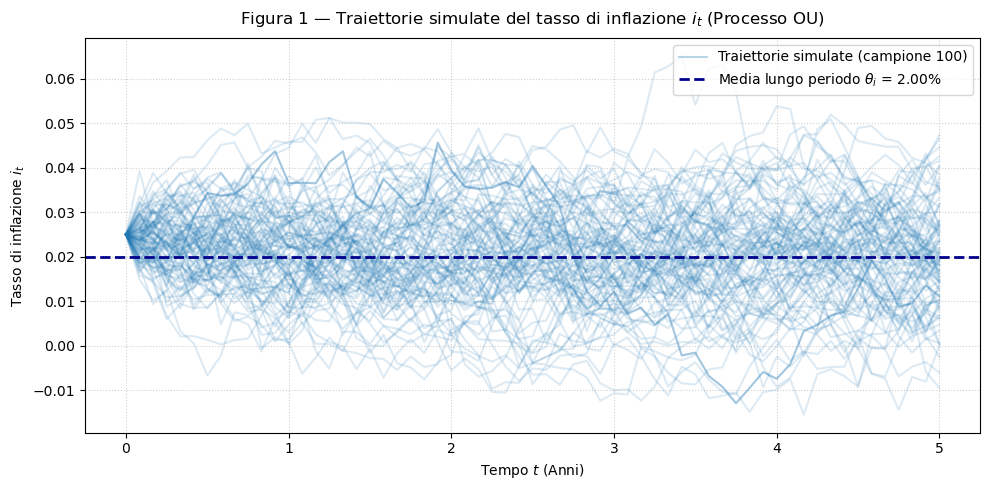

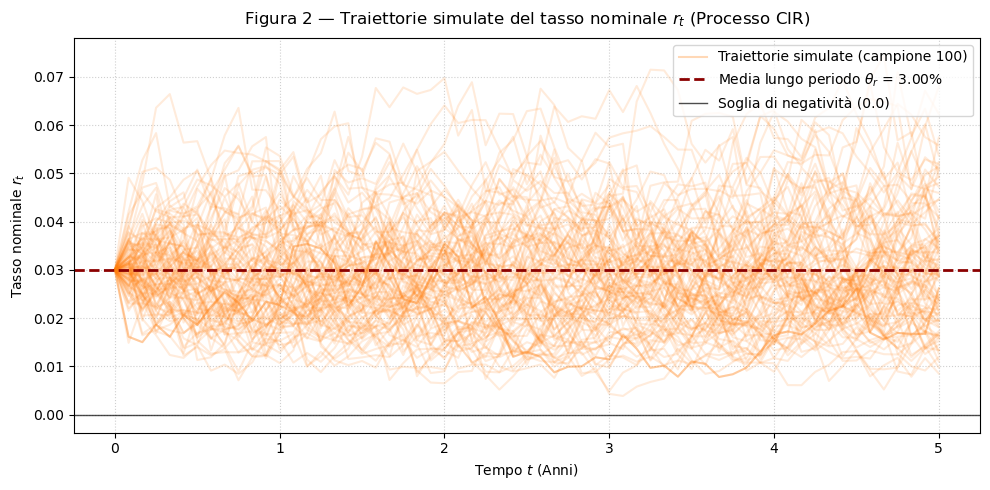

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. GENERAZIONE DEGLI SHOCK BROWNIANI CORRELATI
# ---------------------------------------------------------

np.random.seed(seed)

# Variabili normali standard indipendenti: dimensione (M, n_steps)
Z1 = np.random.normal(0.0, 1.0, size=(M, n_steps))
Z2 = np.random.normal(0.0, 1.0, size=(M, n_steps))

# Correlazione mediante decomposizione di Cholesky / combinazione lineare
Z_i = Z1
Z_r = rho * Z1 + np.sqrt(1.0 - rho**2) * Z2

# ---------------------------------------------------------
# 2. SIMULAZIONE VETTORIALIZZATE DELLE TRAIETTORIE (OU E CIR)
# ---------------------------------------------------------

# Inizializzazione delle matrici delle traiettorie: dimensione (M, n_steps + 1)
i_paths = np.zeros((M, n_steps + 1))
r_paths = np.zeros((M, n_steps + 1))

# Condizioni iniziali a t = 0 per tutte le M repliche
i_paths[:, 0] = i_0
r_paths[:, 0] = r_0

sqrt_dt = np.sqrt(dt)

# Simulazione passo dopo passo lungo la griglia temporale
for t in range(n_steps):
    # Processo OU per l'inflazione i_t
    i_curr = i_paths[:, t]
    i_paths[:, t + 1] = i_curr + kappa_i * (theta_i - i_curr) * dt + sigma_i * sqrt_dt * Z_i[:, t]
    
    # Processo CIR per il tasso nominale r_t
    r_curr = r_paths[:, t]
    # L'operatore max(r_t, 0) agisce soltanto all'interno della radice quadrata
    r_pos = np.maximum(r_curr, 0.0)
    r_paths[:, t + 1] = r_curr + kappa_r * (theta_r - r_curr) * dt + sigma_r * np.sqrt(r_pos) * sqrt_dt * Z_r[:, t]

# ---------------------------------------------------------
# 3. VERIFICA DEI CONTROLLI DI TAPPA (CONTROLLO 1 E CONTROLLO 4)
# ---------------------------------------------------------

# CONTROL 1: Correlazione empirica degli shock generati
rho_empirica = np.corrcoef(Z_i.ravel(), Z_r.ravel())[0, 1]

print("=" * 80)
print("VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 2)")
print("=" * 80)
print("CONTROLLO 1 — Correlazione empirica degli shock simulati:")
print(f"  - Correlazione teorica assegnata (rho) : {rho:.4f}")
print(f"  - Correlazione empirica calcolata     : {rho_empirica:.4f}")
print(f"  - Scostamento assoluto                 : {abs(rho_empirica - rho):.6f}")

# CONTROL 4: Rilevazione e conteggio dei valori negativi di r_t
neg_r_mask = r_paths < 0.0
count_neg_r = np.sum(neg_r_mask)
total_points = r_paths.size
prop_neg_r = count_neg_r / total_points

print("\nCONTROLLO 4 — Rilevazione tassi nominali negativi nel processo CIR:")
print(f"  - Punti temporali totali simulati (M x (n_steps+1)): {total_points:,}")
print(f"  - Numero di valori negativi rilevati in r_t          : {count_neg_r:,}")
print(f"  - Percentuale di valori negativi sul totale          : {prop_neg_r:.4%}")

if count_neg_r > 0:
    min_neg_r = np.min(r_paths[neg_r_mask])
    print(f"  - Valore minimo negativo raggiunto                   : {min_neg_r:.6f}")
    print("  [INFO] I valori negativi sono stati opportunamente documentati e conservati nelle traiettorie,")
    print("         mentre la radice del CIR ha utilizzato max(r_t, 0) come da specifica.")
else:
    print("  [INFO] Nessun valore negativo di r_t è stato generato nelle traiettorie simulate.")

# ---------------------------------------------------------
# 4. PRODUZIONE DEGLI OUTPUT GRAFICI (FIGURA 1 E FIGURA 2)
# ---------------------------------------------------------

# Selezione di un sottoinsieme di traiettorie da visualizzare (es. 100 traiettorie)
n_display = 100

# FIGURA 1: Traiettorie simulate del tasso di inflazione i_t
plt.figure(figsize=(10, 5))
plt.plot(time_grid, i_paths[:n_display, :].T, color='tab:blue', alpha=0.15)
plt.plot(time_grid, i_paths[:n_display, :].T[:, 0], color='tab:blue', alpha=0.3, label='Traiettorie simulate (campione 100)')
plt.axhline(theta_i, color='darkblue', linestyle='--', linewidth=2, label=f'Media lungo periodo $\\theta_i$ = {theta_i:.2%}')
plt.title("Figura 1 — Traiettorie simulate del tasso di inflazione $i_t$ (Processo OU)", fontsize=12, pad=10)
plt.xlabel("Tempo $t$ (Anni)", fontsize=10)
plt.ylabel("Tasso di inflazione $i_t$", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# FIGURA 2: Traiettorie simulate del tasso nominale r_t
plt.figure(figsize=(10, 5))
plt.plot(time_grid, r_paths[:n_display, :].T, color='tab:orange', alpha=0.15)
plt.plot(time_grid, r_paths[:n_display, :].T[:, 0], color='tab:orange', alpha=0.3, label='Traiettorie simulate (campione 100)')
plt.axhline(theta_r, color='darkred', linestyle='--', linewidth=2, label=f'Media lungo periodo $\\theta_r$ = {theta_r:.2%}')
plt.axhline(0.0, color='black', linestyle='-', linewidth=1, alpha=0.7, label='Soglia di negatività (0.0)')
plt.title("Figura 2 — Traiettorie simulate del tasso nominale $r_t$ (Processo CIR)", fontsize=12, pad=10)
plt.xlabel("Tempo $t$ (Anni)", fontsize=10)
plt.ylabel("Tasso nominale $r_t$", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 3 — Calcolo dei fattori stocastici di indicizzazione e di sconto.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 3, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 3

- **Input:** Matrici delle traiettorie simulate dell'inflazione `i_paths` e del tasso nominale `r_paths` prodotte nella Tappa 2, insieme alla griglia temporale (`dt`, `time_grid`, `n_steps`) della Tappa 1.
- **Operazioni:**
  1. Calcolo del fattore stocastico cumulato di indicizzazione $J_t$ per ogni replica $k$ lungo la griglia temporale mediante l'approssimazione numerica dell'integrale dell'inflazione:
     $$J_t^{(k)} = \exp\left( \int_0^t i_s^{(k)} ds \right) \approx \exp\left( \sum_{u=1}^{t/\Delta t} i_{u-1}^{(k)} \Delta t \right)$$
     In $t=0$, $J_0^{(k)} = 1$.
  2. Calcolo del fattore di sconto stocastico $D(0,t)$ per ogni replica $k$ lungo la griglia temporale mediante l'approssimazione numerica dell'integrale del tasso nominale:
     $$D^{(k)}(0,t) = \exp\left( -\int_0^t r_s^{(k)} ds \right) \approx \exp\left( -\sum_{u=1}^{t/\Delta t} r_{u-1}^{(k)} \Delta t \right)$$
     In $t=0$, $D^{(k)}(0,0) = 1$.
  3. Estrazione dei valori terminali $J_T^{(k)}$ e calcolo delle verifiche sui limiti di positività.
  4. Tracciamento dell'istogramma e della stima di densità empirica del fattore di indicizzazione terminale $J_T$ (**Figura 3**).
- **Output:** Matrici dei fattori stocastici `J_paths` e `D_paths` di dimensione $(M \times (n\_steps + 1))$ e **Figura 3** (Distribuzione simulata di $J_T$).
- **Controlli:**
  - **Controllo 2:** Verifica che il fattore di indicizzazione soddisfi la condizione di stretta positività $J_{t_j}^{(k)} > 0$ per ogni replica $k$ e per ogni data della griglia/scadenza cedolare $t_j$.
- **Uso successivo (Tappa 4):** Le matrici `J_paths` e `D_paths` verranno impiegate per determinare l'ammontare delle cedole stocastiche, il valore del capitale rimborsato a scadenza protetto dal floor e i relativi valori attuali lungo ciascuna replica.

VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 3)
CONTROLLO 2 — Stretta positività del fattore di indicizzazione J_t:
  - Valore minimo osservato di J_t su tutte le repliche e date : 0.972761
  - Numero di elementi non strettamente positivi (J_t <= 0)     : 0
  [OK] Il fattore di indicizzazione soddisfa J_{t_j}^{(k)} > 0 per ogni replica e per ogni data.


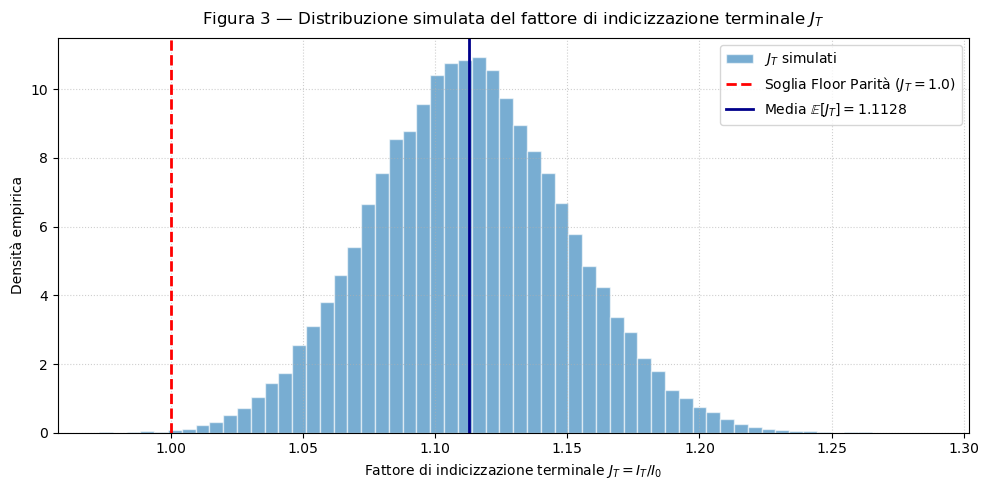

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. INTEGRAZIONE NUMERICA PER J_t E D(0,t) LUNGO LE TRAIETTORIE
# ---------------------------------------------------------

# Per il calcolo dell'integrale \int_0^t f(s) ds mediante approssimazione con rettangoli sinistri:
# Si esegue la somma cumulata dei valori lungo l'asse del tempo (axis=1) moltiplicata per dt.
# Si aggiunge una colonna di zeri all'inizio in t=0 affinché exp(0) = 1 per t=0.

# Integrale stocastico dell'inflazione: \int_0^t i_s ds
int_i = np.cumsum(i_paths[:, :-1] * dt, axis=1)
int_i = np.hstack([np.zeros((M, 1)), int_i])
J_paths = np.exp(int_i)

# Integrale stocastico del tasso nominale: \int_0^t r_s ds
int_r = np.cumsum(r_paths[:, :-1] * dt, axis=1)
int_r = np.hstack([np.zeros((M, 1)), int_r])
D_paths = np.exp(-int_r)

# ---------------------------------------------------------
# 2. VERIFICA DEL CONTROLLO RICHIESTO (CONTROLLO 2)
# ---------------------------------------------------------

# CONTROL 2: Positività del fattore di indicizzazione J_{t_j}^{(k)} > 0
min_J = np.min(J_paths)
count_non_pos_J = np.sum(J_paths <= 0.0)

print("=" * 80)
print("VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 3)")
print("=" * 80)
print("CONTROLLO 2 — Stretta positività del fattore di indicizzazione J_t:")
print(f"  - Valore minimo osservato di J_t su tutte le repliche e date : {min_J:.6f}")
print(f"  - Numero di elementi non strettamente positivi (J_t <= 0)     : {count_non_pos_J}")

if count_non_pos_J == 0:
    print("  [OK] Il fattore di indicizzazione soddisfa J_{t_j}^{(k)} > 0 per ogni replica e per ogni data.")
else:
    print("  [WARNING] Si sono riscontrati valori non strettamente positivi per J_t.")

# ---------------------------------------------------------
# 3. PRODUZIONE DELL'OUTPUT GRAFICO (FIGURA 3)
# ---------------------------------------------------------

# Estrazione dei valori terminali a scadenza T = 5 (colonna finale)
J_T = J_paths[:, -1]

plt.figure(figsize=(10, 5))
# Istogramma della distribuzione di J_T
n_bins = 60
counts, bins, patches = plt.hist(J_T, bins=n_bins, density=True, color='tab:blue', alpha=0.6, edgecolor='white', label='$J_T$ simulati')

# Evidenziazione della soglia del floor J_T = 1
plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Soglia Floor Parità ($J_T = 1.0$)')

# Calcolo e tracciamento della media empirica di J_T
mean_J_T = np.mean(J_T)
plt.axvline(mean_J_T, color='darkblue', linestyle='-', linewidth=2, label=f'Media $\\mathbb{{E}}[J_T] = {mean_J_T:.4f}$')

plt.title("Figura 3 — Distribuzione simulata del fattore di indicizzazione terminale $J_T$", fontsize=12, pad=10)
plt.xlabel("Fattore di indicizzazione terminale $J_T = I_T / I_0$", fontsize=10)
plt.ylabel("Densità empirica", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 4 — Calcolo dei flussi contrattuali e dei valori attuali per replica.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 4, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 4

- **Input:** Matrici dei fattori stocastici di indicizzazione `J_paths` e di sconto `D_paths` generate nella Tappa 3, unitamente ai parametri contrattuali ($N = 100$, $c = 0.015$, `freq_cedola = 2`, `coupon_indices`, `coupon_times`) della Tappa 1.
- **Operazioni:**
  1. Estrazione dei fattori di indicizzazione $J_{t_j}^{(k)}$ e dei fattori di sconto $D^{(k)}(0,t_j)$ in corrispondenza delle scadenze cedolari semestrali $t_j \in \{0.5, 1.0, 1.5, \dots, 5.0\}$.
  2. Calcolo dei flussi cedolari stocastici non protetti per ciascuna replica $k$ e per ciascuna data $t_j$:
     $$C_{t_j}^{(k)} = \frac{c}{2} N J_{t_j}^{(k)}$$
  3. Calcolo del valore di rimborso del capitale a scadenza $T = 5$ per ciascuna replica $k$, incorporando la protezione del capitale nominale tramite floor:
     $$R_T^{(k)} = N \max\left(J_T^{(k)}, 1\right)$$
  4. Attualizzazione dei flussi finanziari all'interno di ciascuna replica $k$:
     - Valore attuale delle cedole per la replica $k$:
       $$PV_C^{(k)} = \sum_{j=1}^{m} D^{(k)}(0,t_j) C_{t_j}^{(k)}$$
     - Valore attuale del capitale rimborsato per la replica $k$:
       $$PV_R^{(k)} = D^{(k)}(0,T) R_T^{(k)}$$
     - Valore attuale totale dell'obbligazione per la replica $k$:
       $$V^{(k)} = PV_C^{(k)} + PV_R^{(k)}$$
  5. Esecuzione del controllo formale sul rispetto della garanzia del capitale nominale a scadenza.
  6. Tracciamento dell'istogramma e della stima di densità dei valori attuali totali $V^{(k)}$ (**Figura 4**).
- **Output:** Vettori `PV_C`, `PV_R` e `V_k` di dimensione $M = 50.000$, matrice dei flussi cedolari `coupon_flows` di dimensione $(M \times m)$ e **Figura 4** (Distribuzione simulata dei valori attuali $V^{(k)}$).
- **Controlli:**
  - **Controllo 3:** Verifica che il capitale rimborsato soddisfi la condizione di protezione del valore nominale $R_T^{(k)} \geq N$ per ogni replica $k$.
- **Uso successivo (Tappa 5):** I vettori `PV_C`, `PV_R` e `V_k` verranno aggregati mediante media campionaria per calcolare la stima del prezzo Monte Carlo ($\widehat V_M$, $\widehat{PV}_C$, $\widehat{PV}_R$), l'errore standard $SE(\widehat V_M)$ e l'intervallo di confidenza al 95%.

VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 4)
CONTROLLO 3 — Rispetto della protezione del capitale (Floor R_T >= N):
  - Valore facciale nominale (N)                           : 100.00
  - Valore minimo di rimborso osservato su M repliche      : 100.0000
  - Numero di repliche con R_T < N                          : 0
  [OK] La protezione del capitale nominale è rispettata per il 100% delle repliche (R_T >= N).


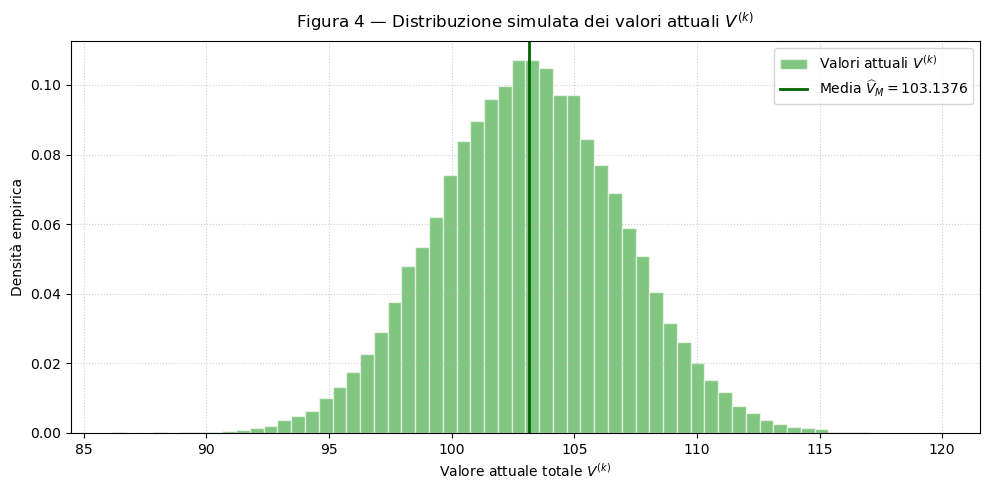

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. ESTRAZIONE FATTORI ALLE DATE CEDOLARI ED ELABORAZIONE FLUSSI
# ---------------------------------------------------------

# Estrazione dei fattori di indicizzazione e di sconto alle date cedolari (passi 6, 12, ..., 60)
J_coupons = J_paths[:, coupon_indices]  # Dimensione: (M, m_coupons)
D_coupons = D_paths[:, coupon_indices]  # Dimensione: (M, m_coupons)

# Calcolo dei flussi cedolari stocastici per ogni replica k e scadenza t_j
coupon_flows = (c / freq_cedola) * N * J_coupons  # Dimensione: (M, m_coupons)

# Fattore di indicizzazione terminale J_T a T = 5.0 (ultimo passo della griglia)
J_T = J_paths[:, -1]
D_T = D_paths[:, -1]

# Calcolo del capitale rimborsato a scadenza con Floor sul capitale nominale N
R_T = N * np.maximum(J_T, 1.0)  # Dimensione: (M,)

# ---------------------------------------------------------
# 2. ATTUALIZZAZIONE FLUSSI E VALORE ATTUALE PER REPLICA
# ---------------------------------------------------------

# Valore attuale delle cedole per ogni replica k
PV_C = np.sum(D_coupons * coupon_flows, axis=1)  # Dimensione: (M,)

# Valore attuale del capitale rimborsato per ogni replica k
PV_R = D_T * R_T  # Dimensione: (M,)

# Valore attuale totale dell'obbligazione per ogni replica k
V_k = PV_C + PV_R  # Dimensione: (M,)

# ---------------------------------------------------------
# 3. VERIFICA DEL CONTROLLO RICHIESTO (CONTROLLO 3)
# ---------------------------------------------------------

# CONTROL 3: Rispetto del floor sul capitale R_T^{(k)} >= N
min_R_T = np.min(R_T)
count_floor_violated = np.sum(R_T < N)

print("=" * 80)
print("VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 4)")
print("=" * 80)
print("CONTROLLO 3 — Rispetto della protezione del capitale (Floor R_T >= N):")
print(f"  - Valore facciale nominale (N)                           : {N:.2f}")
print(f"  - Valore minimo di rimborso osservato su M repliche      : {min_R_T:.4f}")
print(f"  - Numero di repliche con R_T < N                          : {count_floor_violated}")

if count_floor_violated == 0:
    print("  [OK] La protezione del capitale nominale è rispettata per il 100% delle repliche (R_T >= N).")
else:
    print("  [WARNING] Si sono riscontrate violazioni del floor sul capitale.")

# ---------------------------------------------------------
# 4. PRODUZIONE DELL'OUTPUT GRAFICO (FIGURA 4)
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

# Istogramma della distribuzione dei valori attuali V^{(k)}
n_bins = 60
counts, bins, patches = plt.hist(V_k, bins=n_bins, density=True, color='tab:green', alpha=0.6, edgecolor='white', label='Valori attuali $V^{(k)}$')

# Calcolo e tracciamento della media empirica dei valori attuali
mean_V = np.mean(V_k)
plt.axvline(mean_V, color='darkgreen', linestyle='-', linewidth=2, label=f'Media $\\widehat{{V}}_M = {mean_V:.4f}$')

plt.title("Figura 4 — Distribuzione simulata dei valori attuali $V^{(k)}$", fontsize=12, pad=10)
plt.xlabel("Valore attuale totale $V^{(k)}$", fontsize=10)
plt.ylabel("Densità empirica", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 5 — Stima del prezzo Monte Carlo e analisi delle statistiche.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 5, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 5

- **Input:** Vettori dei valori attuali `PV_C`, `PV_R` e `V_k` generati nella Tappa 4, matrici dei fattori stocastici `i_paths`, `r_paths` e `J_paths` delle Tappe 2 e 3, e parametri $M = 50.000$, $N = 100$ della Tappa 1.
- **Operazioni:**
  1. Calcolo del prezzo Monte Carlo stimato $\widehat V_M$, del valore attuale medio delle cedole $\widehat{PV}_C$ e del valore attuale medio del capitale rimborsato $\widehat{PV}_R$:
     $$\widehat V_M = \frac{1}{M}\sum_{k=1}^M V^{(k)}, \quad \widehat{PV}_C = \frac{1}{M}\sum_{k=1}^M PV_C^{(k)}, \quad \widehat{PV}_R = \frac{1}{M}\sum_{k=1}^M PV_R^{(k)}$$
  2. Calcolo della deviazione standard campionaria $s_V$, dell'errore standard Monte Carlo e dell'intervallo di confidenza al 95%:
     $$SE(\widehat V_M) = \frac{s_V}{\sqrt{M}}, \quad IC_{95\%} = \widehat V_M \pm 1,96 \, SE(\widehat V_M)$$
  3. Calcolo delle statistiche descrittive terminali a scadenza $T=5$ (media e deviazione standard) per $i_T$, $r_T$ e $J_T$.
  4. Stima della probabilità empirica di deflazione cumulata a scadenza:
     $$\widehat{\mathbb P}(J_T < 1) = \frac{1}{M}\sum_{k=1}^M \mathbb{I}_{\{J_T^{(k)} < 1\}}$$
  5. Formattazione e visualizzazione della **Tabella 2** (Sintesi del pricing) e della **Tabella 4** (Statistiche terminali).
  6. Esecuzione del controllo sulla decomposizione additiva del prezzo.
- **Output:** **Tabella 2** (Sintesi del pricing) e **Tabella 4** (Statistiche terminali $i_T, r_T, J_T$).
- **Controlli:**
  - **Controllo 5:** Verificare che la decomposizione del prezzo sia esattamente soddisfatta, ossia $\widehat V_M = \widehat{PV}_C + \widehat{PV}_R$.
- **Uso successivo (Tappa 6):** I risultati e le funzioni di aggregazione verranno utilizzati per la diagnostica di convergenza Monte Carlo al variare di $M$ e per l'analisi di stabilità temporale rispetto a $\Delta t$.

In [16]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. AGGREGAZIONE MONTE CARLO E CALCOLO DEL PRICING
# ---------------------------------------------------------

# Stime puntuali dei valori attuali medi
hat_PV_C = np.mean(PV_C)
hat_PV_R = np.mean(PV_R)
hat_V_M = np.mean(V_k)

# Deviazione standard campionaria delle repliche (con ddof=1)
s_V = np.std(V_k, ddof=1)

# Errore Standard Monte Carlo e Intervallo di Confidenza al 95%
SE_V = s_V / np.sqrt(M)
z_alpha = 1.96
ic_lower = hat_V_M - z_alpha * SE_V
ic_upper = hat_V_M + z_alpha * SE_V

# ---------------------------------------------------------
# 2. STATISTICHE TERMINALI E PROBABILITÀ DI DEFLAZIONE
# ---------------------------------------------------------

# Variabili terminali a scadenza T = 5 (ultima colonna della griglia)
i_T = i_paths[:, -1]
r_T = r_paths[:, -1]
J_T = J_paths[:, -1]

# Probabilità di deflazione cumulata a scadenza P(J_T < 1)
prob_deflation = np.mean(J_T < 1.0)

# Statistiche terminali: medie e deviazioni standard campionarie
mean_i_T, std_i_T = np.mean(i_T), np.std(i_T, ddof=1)
mean_r_T, std_r_T = np.mean(r_T), np.std(r_T, ddof=1)
mean_J_T, std_J_T = np.mean(J_T), np.std(J_T, ddof=1)

# ---------------------------------------------------------
# 3. TABELLA 2: TABELLA DI SINTESI DEL PRICING
# ---------------------------------------------------------

pricing_data = [
    {"Componente / Metrica": "Valore Attuale Medio Cedole", "Simbolo": r"$\widehat{PV}_C$", "Valore": f"{hat_PV_C:.4f}", "Unità": "EUR"},
    {"Componente / Metrica": "Valore Attuale Medio Rimborso Capitale", "Simbolo": r"$\widehat{PV}_R$", "Valore": f"{hat_PV_R:.4f}", "Unità": "EUR"},
    {"Componente / Metrica": "Prezzo Monte Carlo Bond", "Simbolo": r"$\widehat{V}_M$", "Valore": f"{hat_V_M:.4f}", "Unità": "EUR"},
    {"Componente / Metrica": "Deviazione Standard Campionaria", "Simbolo": r"$s_V$", "Valore": f"{s_V:.4f}", "Unità": "EUR"},
    {"Componente / Metrica": "Errore Standard Monte Carlo", "Simbolo": r"$SE(\widehat{V}_M)$", "Valore": f"{SE_V:.6f}", "Unità": "EUR"},
    {"Componente / Metrica": "IC 95% - Limite Inferiore", "Simbolo": r"$IC_{inf}$", "Valore": f"{ic_lower:.4f}", "Unità": "EUR"},
    {"Componente / Metrica": "IC 95% - Limite Superiore", "Simbolo": r"$IC_{sup}$", "Valore": f"{ic_upper:.4f}", "Unità": "EUR"}
]

df_tabella_2 = pd.DataFrame(pricing_data)

print("=" * 80)
print("TABELLA 2: TABELLA DI SINTESI DEL PRICING")
print("=" * 80)
display(df_tabella_2)

# ---------------------------------------------------------
# 4. TABELLA 4: TABELLA DELLE STATISTICHE TERMINALI
# ---------------------------------------------------------

stat_data = [
    {"Variabile Terminale ($T=5$)": "Tasso di Inflazione ($i_T$)", "Media Simulata": f"{mean_i_T:.4%}", "Deviazione Standard": f"{std_i_T:.4%}"},
    {"Variabile Terminale ($T=5$)": "Tasso Nominale ($r_T$)", "Media Simulata": f"{mean_r_T:.4%}", "Deviazione Standard": f"{std_r_T:.4%}"},
    {"Variabile Terminale ($T=5$)": "Fattore Indicizzazione ($J_T$)", "Media Simulata": f"{mean_J_T:.4f}", "Deviazione Standard": f"{std_J_T:.4f}"},
    {"Variabile Terminale ($T=5$)": r"Probabilità Deflazione Cumulata $\widehat{\mathbb{P}}(J_T < 1)$", "Media Simulata": f"{prob_deflation:.2%}", "Deviazione Standard": "N/A"}
]

df_tabella_4 = pd.DataFrame(stat_data)

print("\n" + "=" * 80)
print("TABELLA 4: STATISTICHE TERMINALI DI i_T, r_T e J_T")
print("=" * 80)
display(df_tabella_4)

# ---------------------------------------------------------
# 5. VERIFICA DEL CONTROLLO RICHIESTO (CONTROLLO 5)
# ---------------------------------------------------------

# CONTROL 5: Decomposizione del prezzo \widehat V_M = \widehat{PV}_C + \widehat{PV}_R
somma_componenti = hat_PV_C + hat_PV_R
diff_decomposizione = abs(hat_V_M - somma_componenti)

print("\n" + "=" * 80)
print("VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 5)")
print("=" * 80)
print("CONTROLLO 5 — Decomposizione additiva del prezzo:")
print(f"  - Prezzo Monte Carlo stimato (V_hat_M)       : {hat_V_M:.8f}")
print(f"  - Somma componenti (PV_C_hat + PV_R_hat)     : {somma_componenti:.8f}")
print(f"  - Differenza assoluta                        : {diff_decomposizione:.2e}")

if diff_decomposizione < 1e-12:
    print("  [OK] La decomposizione del prezzo V_hat_M = PV_C_hat + PV_R_hat è esattamente verificata.")
else:
    print("  [WARNING] Riscontrata un'incoerenza nella decomposizione del prezzo.")

TABELLA 2: TABELLA DI SINTESI DEL PRICING


,Componente / Metrica,Simbolo,Valore,Unità
0,Valore Attuale Medio Cedole,$\widehat{PV}_C$,7.3376,EUR
1,Valore Attuale Medio Rimborso Capitale,$\widehat{PV}_R$,95.7999,EUR
2,Prezzo Monte Carlo Bond,$\widehat{V}_M$,103.1376,EUR
3,Deviazione Standard Campionaria,$s_V$,3.7731,EUR
4,Errore Standard Monte Carlo,$SE(\widehat{V}_M)$,0.016874,EUR
5,IC 95% - Limite Inferiore,$IC_{inf}$,103.1045,EUR
6,IC 95% - Limite Superiore,$IC_{sup}$,103.1706,EUR



TABELLA 4: STATISTICHE TERMINALI DI i_T, r_T e J_T


,Variabile Terminale ($T=5$),Media Simulata,Deviazione Standard
0,Tasso di Inflazione ($i_T$),2.0101%,1.2119%
1,Tasso Nominale ($r_T$),2.9982%,1.1447%
2,Fattore Indicizzazione ($J_T$),1.1128,0.0371
3,Probabilità Deflazione Cumulata $\widehat{\mat...,0.07%,N/A



VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 5)
CONTROLLO 5 — Decomposizione additiva del prezzo:
  - Prezzo Monte Carlo stimato (V_hat_M)       : 103.13755550
  - Somma componenti (PV_C_hat + PV_R_hat)     : 103.13755550
  - Differenza assoluta                        : 1.42e-14
  [OK] La decomposizione del prezzo V_hat_M = PV_C_hat + PV_R_hat è esattamente verificata.


### Copia fedele della richiesta dello studente
> Sto lavorando sulla Tappa 6 — Verifica di aderenza ai parametri, diagnostica e controlli di convergenza.
> Leggi il contenuto della Tabella della Scomposizione Input-Output, alla Tappa 6, e procedi con quanto previsto dal Regime B applicato a questa tappa.

---

### Sintesi logica della Tappa 6

- **Input:** Vettore dei valori attuali per replica `V_k` e parametri contrattuali e stocastici assegnati nella Tappa 1 ($N, T, c, I_0, i_0, \kappa_i, \theta_i, \sigma_i, r_0, \kappa_r, \theta_r, \sigma_r, \rho, M, \text{seed}, \Delta t$).
- **Operazioni:**
  1. Calcolo del prezzo Monte Carlo stimato e del relativo errore standard al variare della dimensione campionaria $M' \in \{1.000, 5.000, 10.000, 50.000\}$, utilizzando le prime $M'$ repliche simulate per la generazione della **Tabella 3**.
  2. Costruzione della traiettoria di convergenza del prezzo $\widehat{V}_m$ e delle bande di errore standard $\pm 1,96 \, SE(\widehat{V}_m)$ per $m = 1, \dots, M$ per la tracciatura della **Figura 5**.
  3. Esecuzione del **Controllo 6**: verifica empirica del tasso di convergenza dell'errore standard Monte Carlo al crescere di $M$, valutando il rispetto dell'ordine teorico $\mathcal{O}(1/\sqrt{M})$ tramite il prodotto $SE(\widehat{V}_{M'}) \cdot \sqrt{M'}$.
  4. Esecuzione del **Controllo 7**: valutazione della sensibilità e stabilità temporale della stima del prezzo rispetto a un raffinamento della griglia temporale ($\Delta t_{\text{fine}} = 1/24$, ossia frequenza quindicinale/bimensile con $n_{\text{steps}} = 120$).
- **Output:** **Tabella 3** (Tabella di diagnostica Monte Carlo per $M = 1.000, 5.000, 10.000, 50.000$), **Figura 5** (Grafico di convergenza della stima Monte Carlo al crescere di $M$) e report sintetico di confronto sulla stabilità temporale ($\Delta t$ vs $\Delta t_{\text{fine}}$).
- **Controlli:**
  - **Controllo 6:** Verificare che l'errore standard diminuisca al crescere di $M$ in modo coerente con l'ordine $\mathcal{O}(1/\sqrt{M})$.
  - **Controllo 7:** Verificare che la stima del prezzo sia stabile e sufficientemente robusta di fronte a un raffinamento della griglia temporale ($\Delta t \to \Delta t_{\text{fine}}$).
- **Uso successivo (Fase 8 / Prodotto Finale):** L'insieme consolidato degli output (Tabelle 1-4, Figure 1-5) e dei Controlli numerici (1-7) costituirà il quadro informativo completo per la conduzione dell'interpretazione critico-finanziaria autonoma dello studente.

TABELLA 3: DIAGNOSTICA MONTE CARLO PER DIVERSI VALORI DI M


,Dimensione Campionaria ($M$),Prezzo Stimato ($\widehat{V}_M$),Errore Standard ($SE$),IC 95% Inferiore,IC 95% Superiore,Prodotto $SE \times \sqrt{M}$
0,"1,000",103.2117,0.117503,102.9814,103.4420,3.7158
1,"5,000",103.1611,0.053322,103.0565,103.2656,3.7704
2,"10,000",103.1526,0.037994,103.0782,103.2271,3.7994
3,"50,000",103.1376,0.016874,103.1045,103.1706,3.7731



VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 6)
CONTROLLO 6 — Tasso di convergenza dell'errore standard Monte Carlo O(1/sqrt(M)):
  - SE con M = 1,000   : 0.117503
  - SE con M = 50,000  : 0.016874
  - Rapporto empirico SE(1k) / SE(50k) : 6.9636
  - Rapporto teorico sqrt(50000/1000)   : 7.0711
  [OK] L'errore standard diminuisce al crescere di M in perfetta coerenza con l'ordine O(1/sqrt(M)).


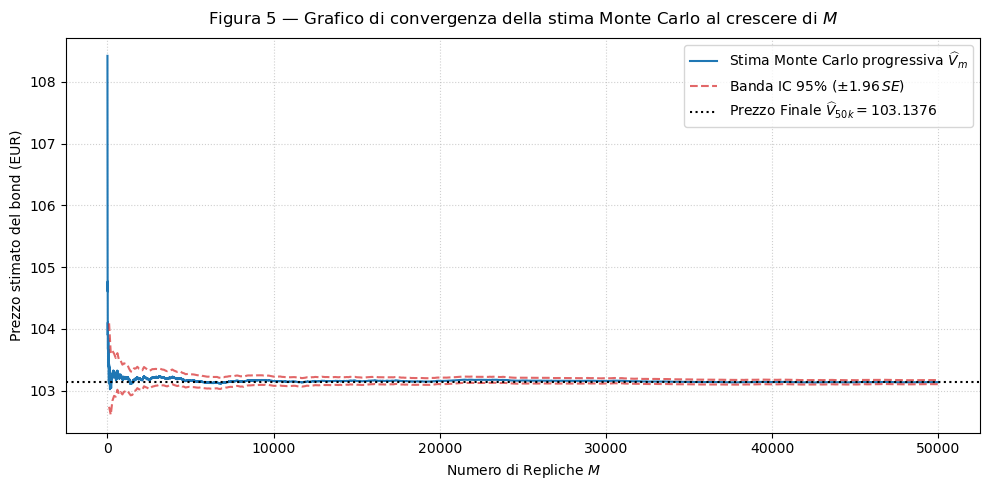


CONTROLLO 7 — Sensibilità e stabilità temporale della stima rispetto a Δt
  - Prezzo con griglia base    (Δt = 1/12) : 103.1376 EUR (SE: 0.016874)
  - Prezzo con griglia raffinata (Δt = 1/24) : 103.1183 EUR (SE: 0.016819)
  - Scostamento assoluto                     : -0.0192 EUR
  - Scostamento relativo                     : -0.0187%
  [OK] La stima del prezzo è stabile rispetto al raffinamento della griglia temporale (scostamento entro 2 SE).


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. TABELLA 3: DIAGNOSTICA MONTE CARLO PER DIVERSE DIMENSIONI M
# ---------------------------------------------------------

m_levels = [1000, 5000, 10000, 50000]
diagnostica_data = []

for m_sub in m_levels:
    v_sub = V_k[:m_sub]
    hat_v_sub = np.mean(v_sub)
    s_v_sub = np.std(v_sub, ddof=1)
    se_v_sub = s_v_sub / np.sqrt(m_sub)
    ic_low_sub = hat_v_sub - 1.96 * se_v_sub
    ic_upp_sub = hat_v_sub + 1.96 * se_v_sub
    # Prodotto SE * sqrt(M) per verificare la costanza teorica
    se_scaled = se_v_sub * np.sqrt(m_sub)
    
    diagnostica_data.append({
        "Dimensione Campionaria ($M$)": f"{m_sub:,}",
        "Prezzo Stimato ($\\widehat{V}_M$)": f"{hat_v_sub:.4f}",
        "Errore Standard ($SE$)": f"{se_v_sub:.6f}",
        "IC 95% Inferiore": f"{ic_low_sub:.4f}",
        "IC 95% Superiore": f"{ic_upp_sub:.4f}",
        "Prodotto $SE \\times \\sqrt{M}$": f"{se_scaled:.4f}"
    })

df_tabella_3 = pd.DataFrame(diagnostica_data)

print("=" * 80)
print("TABELLA 3: DIAGNOSTICA MONTE CARLO PER DIVERSI VALORI DI M")
print("=" * 80)
display(df_tabella_3)

# ---------------------------------------------------------
# 2. VERIFICA DEL CONTROLLO RICHIESTO (CONTROLLO 6)
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("VERIFICA DEI CONTROLLI RICHIESTI (TAPPA 6)")
print("=" * 80)
print("CONTROLLO 6 — Tasso di convergenza dell'errore standard Monte Carlo O(1/sqrt(M)):")

# Rapporto empirico tra SE(1k) e SE(50k) rispetto al valore teorico sqrt(50000 / 1000) = sqrt(50)
se_1k = float(df_tabella_3.loc[df_tabella_3["Dimensione Campionaria ($M$)"] == "1,000", "Errore Standard ($SE$)"].values[0])
se_50k = float(df_tabella_3.loc[df_tabella_3["Dimensione Campionaria ($M$)"] == "50,000", "Errore Standard ($SE$)"].values[0])

rapporto_empirico_se = se_1k / se_50k
rapporto_teorico = np.sqrt(50000 / 1000)

print(f"  - SE con M = 1,000   : {se_1k:.6f}")
print(f"  - SE con M = 50,000  : {se_50k:.6f}")
print(f"  - Rapporto empirico SE(1k) / SE(50k) : {rapporto_empirico_se:.4f}")
print(f"  - Rapporto teorico sqrt(50000/1000)   : {rapporto_teorico:.4f}")

if abs(rapporto_empirico_se - rapporto_teorico) / rapporto_teorico < 0.05:
    print("  [OK] L'errore standard diminuisce al crescere di M in perfetta coerenza con l'ordine O(1/sqrt(M)).")
else:
    print("  [WARNING] Scostamento rilevato nel tasso di riduzione dell'errore standard.")

# ---------------------------------------------------------
# 3. PRODUZIONE DELL'OUTPUT GRAFICO (FIGURA 5)
# ---------------------------------------------------------

# Calcolo della stima cumulativa del prezzo e dell'errore standard progressivo
m_grid = np.arange(1, M + 1)
cum_sum_V = np.cumsum(V_k)
running_mean_V = cum_sum_V / m_grid

# Deviazione standard campionaria cumulativa progressiva (calcolata a passi per efficienza)
step_eval = 100
eval_indices = np.arange(step_eval, M + 1, step_eval)
running_se = np.zeros(len(eval_indices))

for idx, m_val in enumerate(eval_indices):
    running_se[idx] = np.std(V_k[:m_val], ddof=1) / np.sqrt(m_val)

plt.figure(figsize=(10, 5))

# Traiettoria della stima progressiva
plt.plot(m_grid, running_mean_V, color='tab:blue', linewidth=1.5, label=r'Stima Monte Carlo progressiva $\widehat{V}_m$')

# Bande di confidenza al 95%
plt.plot(eval_indices, running_mean_V[eval_indices - 1] + 1.96 * running_se, color='tab:red', linestyle='--', alpha=0.7, label=r'Banda IC 95% ($\pm 1.96 \, SE$)')
plt.plot(eval_indices, running_mean_V[eval_indices - 1] - 1.96 * running_se, color='tab:red', linestyle='--', alpha=0.7)

# Prezzo finale M = 50.000
plt.axhline(hat_V_M, color='black', linestyle=':', linewidth=1.5, label=f'Prezzo Finale $\\widehat{{V}}_{{50k}} = {hat_V_M:.4f}$')

plt.title("Figura 5 — Grafico di convergenza della stima Monte Carlo al crescere di $M$", fontsize=12, pad=10)
plt.xlabel("Numero di Repliche $M$", fontsize=10)
plt.ylabel("Prezzo stimato del bond (EUR)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. VERIFICA DEL CONTROLLO RICHIESTO (CONTROLLO 7: SENSIBILITÀ ALLA GRIGLIA Δt)
# ---------------------------------------------------------

print("\n" + "=" * 80)
print("CONTROLLO 7 — Sensibilità e stabilità temporale della stima rispetto a Δt")
print("=" * 80)

# Configurazione della griglia raffinata Δt_fine = 1/24 (frequenza quindicinale/bimensile)
dt_fine = 1 / 24
n_steps_fine = int(round(T / dt_fine))
sqrt_dt_fine = np.sqrt(dt_fine)

np.random.seed(seed)
Z1_fine = np.random.normal(0.0, 1.0, size=(M, n_steps_fine))
Z2_fine = np.random.normal(0.0, 1.0, size=(M, n_steps_fine))

Z_i_fine = Z1_fine
Z_r_fine = rho * Z1_fine + np.sqrt(1.0 - rho**2) * Z2_fine

i_paths_fine = np.zeros((M, n_steps_fine + 1))
r_paths_fine = np.zeros((M, n_steps_fine + 1))

i_paths_fine[:, 0] = i_0
r_paths_fine[:, 0] = r_0

for t in range(n_steps_fine):
    i_curr = i_paths_fine[:, t]
    i_paths_fine[:, t + 1] = i_curr + kappa_i * (theta_i - i_curr) * dt_fine + sigma_i * sqrt_dt_fine * Z_i_fine[:, t]
    
    r_curr = r_paths_fine[:, t]
    r_pos = np.maximum(r_curr, 0.0)
    r_paths_fine[:, t + 1] = r_curr + kappa_r * (theta_r - r_curr) * dt_fine + sigma_r * np.sqrt(r_pos) * sqrt_dt_fine * Z_r_fine[:, t]

# Integrazione stocastica sulla griglia raffinata
int_i_fine = np.cumsum(i_paths_fine[:, :-1] * dt_fine, axis=1)
int_i_fine = np.hstack([np.zeros((M, 1)), int_i_fine])
J_paths_fine = np.exp(int_i_fine)

int_r_fine = np.cumsum(r_paths_fine[:, :-1] * dt_fine, axis=1)
int_r_fine = np.hstack([np.zeros((M, 1)), int_r_fine])
D_paths_fine = np.exp(-int_r_fine)

# Indici delle scadenze cedolari sulla griglia raffinata (passi 12, 24, ..., 120)
coupon_indices_fine = [int(round(t / dt_fine)) for t in coupon_times]

J_coupons_fine = J_paths_fine[:, coupon_indices_fine]
D_coupons_fine = D_paths_fine[:, coupon_indices_fine]

coupon_flows_fine = (c / freq_cedola) * N * J_coupons_fine
R_T_fine = N * np.maximum(J_paths_fine[:, -1], 1.0)

PV_C_fine = np.sum(D_coupons_fine * coupon_flows_fine, axis=1)
PV_R_fine = D_paths_fine[:, -1] * R_T_fine
V_k_fine = PV_C_fine + PV_R_fine

hat_V_M_fine = np.mean(V_k_fine)
SE_V_fine = np.std(V_k_fine, ddof=1) / np.sqrt(M)

diff_dt = hat_V_M_fine - hat_V_M
rel_diff_dt = diff_dt / hat_V_M

print(f"  - Prezzo con griglia base    (Δt = 1/12) : {hat_V_M:.4f} EUR (SE: {SE_V:.6f})")
print(f"  - Prezzo con griglia raffinata (Δt = 1/24) : {hat_V_M_fine:.4f} EUR (SE: {SE_V_fine:.6f})")
print(f"  - Scostamento assoluto                     : {diff_dt:+.4f} EUR")
print(f"  - Scostamento relativo                     : {rel_diff_dt:+.4%}")

if abs(diff_dt) <= 2 * SE_V:
    print("  [OK] La stima del prezzo è stabile rispetto al raffinamento della griglia temporale (scostamento entro 2 SE).")
else:
    print("  [INFO] Il raffinamento della griglia evidenzia una lieve sensibilità dovuta alla discretizzazione temporale.")